# Maintenance prédictive d'une vanne hydraulique

Projet de Machine Learning, ING2 BDML, EFREI 2026 / 2027.

Ce notebook présente le projet de bout en bout : le problème, les données, nos choix, les modèles testés et le modèle retenu. Chaque choix est justifié par une mesure. Le code détaillé des fonctions est dans `src/`, les explorations complètes dans `notebooks/`.

## Résumé

## 1. Le problème

Une machine hydraulique tourne par cycles de 60 secondes. Sa vanne s'use : elle passe de 100 % (fonctionnement optimal) à 90 %, 80 % puis 73 %. Une vanne dégradée finit par provoquer une panne et un arrêt de production.

**Objectif** : prédire, pour chaque cycle, si la vanne est optimale (100 %) ou non, à partir de deux capteurs seulement. Si c'est possible, l'usine peut planifier le remplacement de la vanne avant la panne.

| Fichier | Contenu | Taille |
|---|---|---|
| `PS2.txt` | pression en bar, 100 mesures par seconde | 2205 cycles x 6000 valeurs |
| `FS1.txt` | débit en litres par minute, 10 mesures par seconde | 2205 cycles x 600 valeurs |
| `profile.txt` | état de 5 composants, dont la vanne | 2205 cycles x 5 colonnes |

**Consigne** : les 2000 premiers cycles servent à construire le modèle, les 205 derniers sont l'échantillon de test final.

In [1]:
%load_ext autoreload
%autoreload 2

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report
from sklearn.model_selection import StratifiedKFold, learning_curve
from sklearn.tree import DecisionTreeClassifier

from src.utils import (load_data, save_figure, make_binary_target, missing_summary,
                       class_distribution, count_outliers_iqr, build_feature_set,
                       split_first_n, select_features, plot_class_distribution,
                       plot_correlation_matrix, plot_boxplots, FEATURE_SETS)
from src.model import get_baseline_models, get_ensemble_models
from src.train import compare_models, tune_all, tune_model
from src.evaluation import test_scores, plot_confusion_matrices, plot_roc_curves

# Avertissements de convergence sans impact sur les résultats
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 20)

## 2. Les données

### 2.1 Chargement et qualité

In [2]:
PS2 = load_data("data/raw/PS2.txt")
FS1 = load_data("data/raw/FS1.txt")
profile = load_data("data/raw/profile.txt")
profile.columns = ["cooler", "valve", "pump", "accumulator", "stable"]

print("PS2    :", PS2.shape, "(cycles x mesures)")
print("FS1    :", FS1.shape, "(cycles x mesures)")
print("profile:", profile.shape)
missing_summary({"PS2": PS2, "FS1": FS1, "profile": profile})

PS2    : (2205, 6000) (cycles x mesures)
FS1    : (2205, 600) (cycles x mesures)
profile: (2205, 5)


,valeurs_manquantes,cellules
PS2,0,13230000
FS1,0,1323000
profile,0,11025


Aucune valeur manquante. Toutes les colonnes sont numériques : il n'y a **aucune variable catégorielle à encoder**. Les colonnes de `profile` sont des niveaux d'état codés par des nombres (100, 90, 80, 73 pour la vanne).

In [3]:
profile.nunique().to_frame("nombre de valeurs différentes")

,nombre de valeurs différentes
cooler,3
valve,4
pump,3
accumulator,4
stable,2


### 2.2 La cible

On transforme l'état de la vanne en classification binaire : `y = 1` si la vanne est à 100 %, `y = 0` sinon.

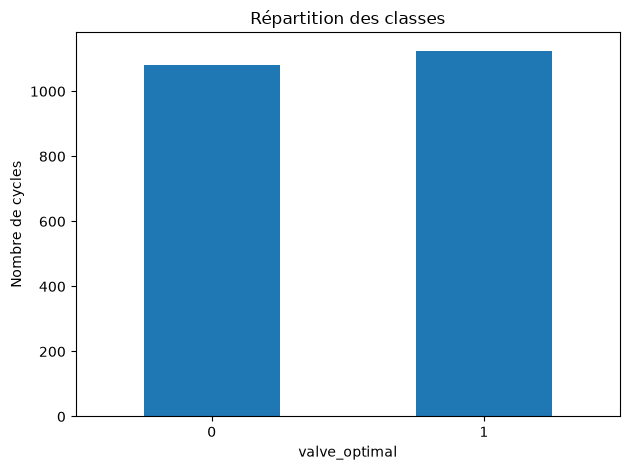

,n,%
valve_optimal,,
0,1080,49.0
1,1125,51.0


In [4]:
y = make_binary_target(profile["valve"], positive_value=100, name="valve_optimal")
plot_class_distribution(y, save_as="projet_repartition_classes.png")

Sur l'ensemble des cycles, les classes sont équilibrées (environ 51 % / 49 %). Pas besoin de rééchantillonner. Par précaution, les modèles qui le permettent utilisent `class_weight="balanced"`, et on suit le **F1 macro**, qui donne le même poids aux deux classes.

## 3. Le découpage, décidé avant tout le reste

On fixe le découpage **avant** de construire ou sélectionner les features. Tout ce qui est appris (bornes des histogrammes, colonnes gardées, standardisation, modèles) l'est sur les 2000 premiers cycles uniquement. Sinon, le test influencerait le modèle et son score serait trop optimiste.

Avant de modéliser, on regarde à quoi ressemblent les 205 cycles du test.

In [5]:
partie = pd.Series(np.where(profile.index < 2000, "train", "test"), index=profile.index)

pd.concat({composant: pd.crosstab(profile[composant], partie, normalize="columns")[["train", "test"]].mul(100).round(1)
           for composant in ["valve", "cooler", "accumulator"]})

col_0            train   test
valve       73    16.0   19.5
            80    15.9   20.5
            90    15.5   24.4
            100   52.6   35.6
cooler      3     36.6    0.0
            20    36.6    0.0
            100   26.8  100.0
accumulator 90    33.3   69.3
            100   16.8   30.7
            115   20.0    0.0
            130   30.0    0.0

**Le test ne ressemble pas au train** :

- 36 % de vannes optimales dans le test, contre 53 % dans le train ;
- le refroidisseur est toujours à 100 % dans le test, contre 27 % des cycles du train ;
- l'accumulateur ne prend que 2 de ses 4 valeurs.

C'est un **décalage de distribution**. Le test est donc plus difficile qu'un tirage aléatoire, mais plus honnête : il simule des cycles futurs, enregistrés dans des conditions que le modèle n'a pas toutes vues.

Pour choisir les modèles, on utilise donc une **validation croisée à 5 plis sur les 2000 cycles du train**. Le test n'est utilisé qu'une seule fois, à la fin, pour mesurer la performance du modèle retenu.

## 4. Du signal brut aux features

### 4.1 Ce que voit le capteur de pression

Un cycle de pression contient 6000 valeurs. On trace la pression moyenne des 12 premières secondes du cycle pour chaque état de la vanne (train uniquement).

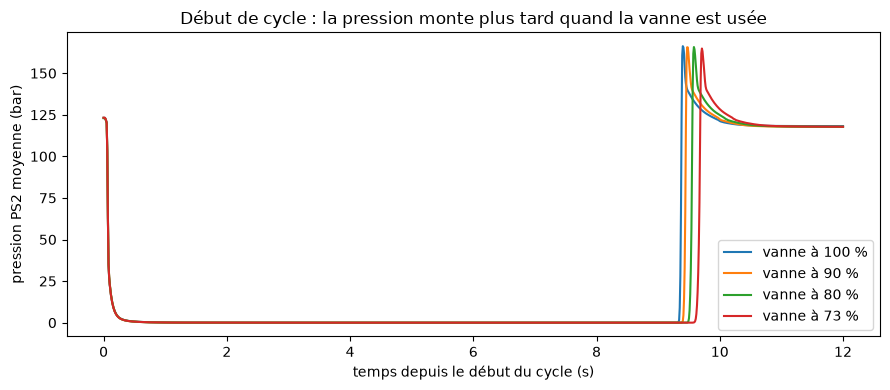

In [6]:
temps = np.arange(PS2.shape[1]) / 100          # 100 mesures par seconde
debut = temps <= 12

plt.figure(figsize=(9, 4))
for niveau in [100, 90, 80, 73]:
    cycles = PS2[:2000][profile["valve"][:2000] == niveau]
    plt.plot(temps[debut], cycles.mean().values[debut], label=f"vanne à {niveau} %")
plt.xlabel("temps depuis le début du cycle (s)")
plt.ylabel("pression PS2 moyenne (bar)")
plt.legend()
plt.title("Début de cycle : la pression monte plus tard quand la vanne est usée")
save_figure("projet_pression_debut_cycle.png")
plt.show()

La différence entre les états de la vanne est visible à l'oeil : **plus la vanne est usée, plus la pression met de temps à monter** en début de cycle. L'écart est de quelques dixièmes de seconde. Il faut des features capables de capter un détail aussi fin.

### 4.2 Quatre façons de résumer un cycle

6600 valeurs par cycle, c'est trop pour 2000 exemples, et les valeurs voisines sont presque identiques. On résume chaque cycle par quelques nombres. Nous avons testé quatre méthodes :

| Jeu | Idée | Features brutes |
|---|---|---|
| `stats` | statistiques de chaque signal : min, max, moyenne, écart type, quartiles, asymétrie, aplatissement, plus le rapport pression / débit | 23 |
| `spectre` | transformée de Fourier : amplitude maximale, fréquence dominante, énergie, centre du spectre | 8 |
| `stats_spectre` | les deux précédents ensemble | 30 |
| `histogramme` | part du cycle passée dans chacun des 20 intervalles de valeurs, pour chaque capteur | 40 |

L'histogramme compte combien de temps le signal passe dans chaque plage de valeurs. Il capte directement le phénomène vu sur le graphique : le temps passé à basse pression.

In [7]:
jeux = {}
for nom in FEATURE_SETS:
    X = build_feature_set(nom, PS2, FS1, n_fit=2000)     # bornes des histogrammes : train seulement
    x_train, x_test, y_train, y_test = split_first_n(X, y, n_train=2000)
    x_train, x_test, supprimees = select_features(x_train, x_test)
    jeux[nom] = (x_train, x_test, y_train, y_test)
    print(f"{nom:14s} {X.shape[1]:3d} features brutes -> {x_train.shape[1]:2d} gardées")

stats           23 features brutes ->  7 gardées


spectre          8 features brutes ->  3 gardées


stats_spectre   30 features brutes ->  9 gardées


histogramme     40 features brutes -> 14 gardées


### 4.3 Sélection des features

Deux règles simples, appliquées sur le train :

1. supprimer les features quasi constantes (écart type inférieur à 0.001) : elles ne distinguent aucun cycle ;
2. supprimer une feature de chaque paire trop corrélée (corrélation absolue supérieure à 0.85) : elles portent la même information et rendent les modèles linéaires instables.

Matrice de corrélation des 14 features gardées pour le jeu `histogramme` :

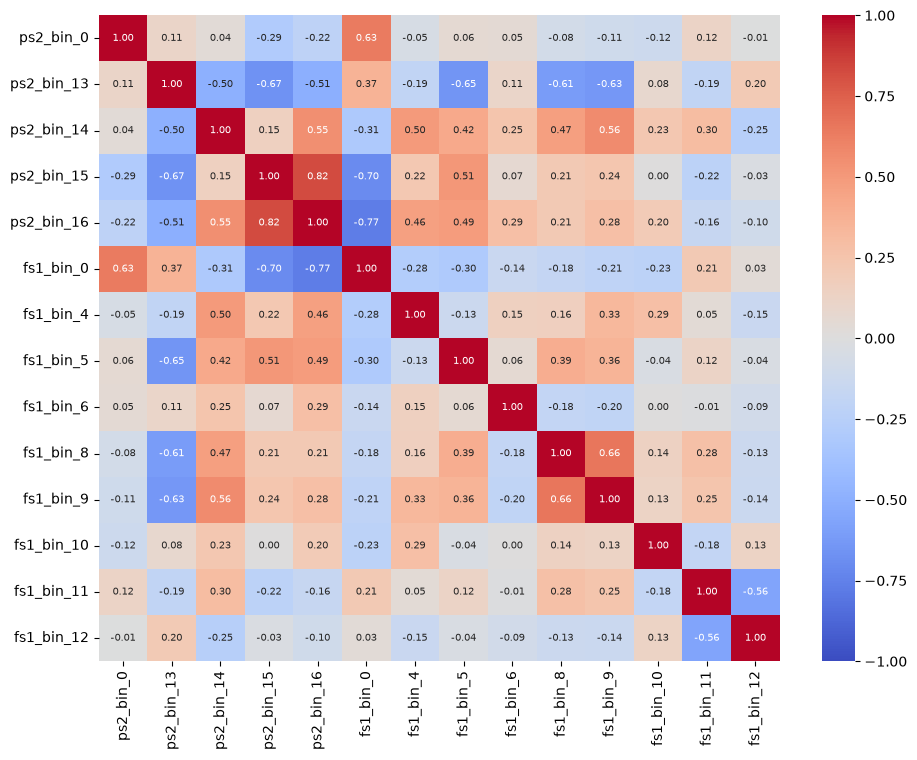

In [8]:
x_train_h = jeux["histogramme"][0]
plot_correlation_matrix(x_train_h, save_as="projet_correlation_histogramme.png")

## 5. Valeurs aberrantes

On compte les valeurs hors de l'intervalle [Q1 - 1.5 x IQR ; Q3 + 1.5 x IQR] sur le jeu `stats`, le plus lisible physiquement.

In [9]:
count_outliers_iqr(jeux["stats"][0]).head(8)

,n_outliers,%
ps2_mean,240,12.0
fs1_kurtosis,183,9.2
fs1_max,69,3.4
ps2_max,44,2.2
ps2_median,14,0.7
fs1_q75,11,0.6
ps2_q25,0,0.0


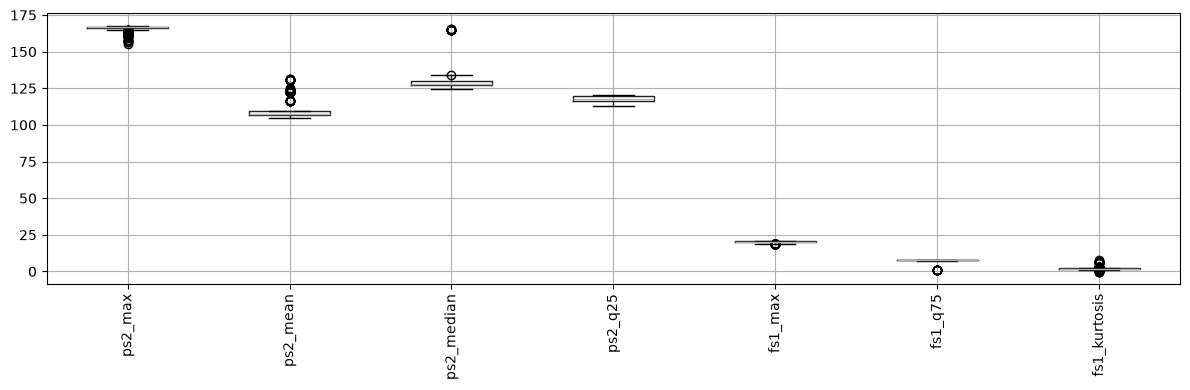

In [10]:
plot_boxplots(jeux["stats"][0], figsize=(12, 4), save_as="projet_boxplots_stats.png")

**Décision : on garde les valeurs aberrantes.** Ce ne sont pas des erreurs de mesure mais des cycles réels, souvent liés à l'état d'un composant. Les supprimer reviendrait à retirer des exemples de pannes, justement ce qu'on veut détecter. Pour limiter leur effet :

- les modèles sensibles aux écarts d'échelle (régression logistique, k plus proches voisins, SVM) sont précédés d'une standardisation ;
- les modèles à base d'arbres coupent sur des seuils et sont peu sensibles aux valeurs extrêmes.

## 6. Les modèles et pourquoi

| Modèle | Type | Points forts pour nos données | Points faibles |
|---|---|---|---|
| Régression logistique | linéaire | simple, rapide, interprétable, bonne référence | ne trace qu'une frontière droite |
| k plus proches voisins | non linéaire, par distance | aucune hypothèse sur la forme des données | sensible à l'échelle et aux features inutiles |
| Arbre de décision | non linéaire, par seuils | lisible, insensible à l'échelle, adapté aux seuils physiques | instable, surapprend facilement |
| Naive Bayes | probabiliste | très rapide | suppose les features indépendantes et gaussiennes, faux ici |
| SVM (noyau RBF) | non linéaire, par marge | frontières complexes, robuste en dimension moyenne | lent sur de gros volumes, à régler finement |
| Ensembles (bagging, boosting, vote, stacking) | combinaison de modèles | réduisent la variance (bagging) ou le biais (boosting) | moins interprétables, plus lents |

Nos features sont continues, en nombre modéré (3 à 14), avec 2000 exemples. Le phénomène recherché est un **seuil** (un temps à basse pression plus long que la normale) : on s'attend à ce que les arbres et leurs ensembles soient bien placés.

## 7. Premier tri : quel jeu de features ?

Tous les modèles, avec leurs réglages par défaut, sur les 4 jeux. On compare le **F1 macro en validation croisée sur le train**, sans regarder le test.

In [11]:
def tous_les_modeles():
    """Modèles simples et modèles d'ensemble, réglages par défaut."""
    simples = get_baseline_models()
    simples.pop("random_forest")          # déjà présent dans les ensembles
    return {**simples, **get_ensemble_models()}

cv_par_jeu = {}
for nom, (x_tr, x_te, y_tr, y_te) in jeux.items():
    res, _ = compare_models(tous_les_modeles(), x_tr, y_tr, x_te, y_te)
    cv_par_jeu[nom] = res["cv_f1_macro"]

cv_par_jeu = pd.DataFrame(cv_par_jeu)
cv_par_jeu.sort_values("histogramme", ascending=False).round(3)

,stats,spectre,stats_spectre,histogramme
model,,,,
random_forest,0.980,0.975,0.983,0.998
gradient_boosting,0.985,0.976,0.989,0.997
adaboost,0.848,0.969,0.965,0.997
extra_trees,0.984,0.977,0.988,0.996
bagging,0.970,0.980,0.978,0.996
decision_tree,0.954,0.974,0.969,0.995
vote_soft,0.938,0.959,0.982,0.994
stacking,0.964,0.973,0.977,0.992
logistic_regression,0.728,0.837,0.942,0.988


In [12]:
cv_par_jeu.agg(["mean", "max"]).round(3)

,stats,spectre,stats_spectre,histogramme
mean,0.884,0.917,0.957,0.981
max,0.985,0.980,0.989,0.998


## 8. Optimisation des hyperparamètres

In [13]:
x_train, x_test, y_train, y_test = jeux["histogramme"]

# Grid search : toutes les combinaisons de la grille, validation croisée stratifiée à 5 plis sur le train
resultats_grid, modeles_regles = tune_all(x_train, y_train, x_test, y_test, search="grid")
resultats_grid[["cv_f1_macro", "search_time_s", "best_params"]].sort_values("cv_f1_macro", ascending=False)

,cv_f1_macro,search_time_s,best_params
model,,,
random_forest,0.997494,41.004465,"{'clf__max_depth': None, 'clf__max_features': ..."
svm,0.996490,1.226871,"{'clf__C': 100, 'clf__gamma': 0.01, 'clf__kern..."
decision_tree,0.995990,1.055938,"{'clf__criterion': 'entropy', 'clf__max_depth'..."
logistic_regression,0.991975,0.928651,{'clf__C': 10}
knn,0.964427,16.088655,"{'clf__n_neighbors': 15, 'clf__p': 1, 'clf__we..."
naive_bayes,0.897485,0.208902,{'clf__var_smoothing': 1e-11}


Le random search teste seulement un nombre fixé de combinaisons tirées au hasard. Comparaison sur la forêt aléatoire, la grille la plus longue (36 combinaisons) :

In [14]:
for search, n_iter in [("grid", None), ("random", 10)]:
    kwargs = {"n_iter": n_iter} if n_iter else {}
    debut = pd.Timestamp.now()
    _, params, table = tune_model("random_forest", x_train, y_train, search=search, **kwargs)
    duree = (pd.Timestamp.now() - debut).total_seconds()
    print(f"{search:6s} : {len(table):2d} combinaisons, {duree:5.1f} s, meilleur F1 CV = {table.loc[0, 'mean_test_score']:.4f}")

grid   : 36 combinaisons,  38.9 s, meilleur F1 CV = 0.9975


random : 10 combinaisons,   9.5 s, meilleur F1 CV = 0.9975


On règle aussi les deux modèles de boosting, qui ont des grilles dédiées dans `src/model.py`.

In [15]:
for nom in ["gradient_boosting", "adaboost"]:
    modele, params, table = tune_model(nom, x_train, y_train)
    modeles_regles[nom] = modele
    print(f"{nom:18s} F1 CV = {table.loc[0, 'mean_test_score']:.4f}  {params}")

gradient_boosting  F1 CV = 0.9975  {'clf__learning_rate': 0.03, 'clf__max_depth': None, 'clf__max_iter': 300}


adaboost           F1 CV = 0.9975  {'clf__learning_rate': 1.0, 'clf__n_estimators': 500}


## 9. Ensemble learning

On compare les modèles réglés aux modèles d'ensemble restants (bagging, extra trees, vote, stacking), toujours en validation croisée sur le train.

In [16]:
ensembles = get_ensemble_models()
candidats = {**modeles_regles,
             **{nom: ensembles[nom] for nom in ["bagging", "extra_trees", "vote_soft", "stacking"]}}

comparaison, entraines = compare_models(candidats, x_train, y_train, x_test, y_test)
choix_cv = comparaison[["train_f1_macro", "cv_f1_macro", "cv_std", "fit_time_s"]].sort_values(
    ["cv_f1_macro", "cv_std"], ascending=[False, True])
choix_cv.round(4)

,train_f1_macro,cv_f1_macro,cv_std,fit_time_s
model,,,,
random_forest,1.0000,0.9975,0.0032,0.4474
gradient_boosting,1.0000,0.9975,0.0022,1.3753
adaboost,1.0000,0.9975,0.0032,2.0448
extra_trees,1.0000,0.9965,0.0026,0.8340
bagging,1.0000,0.9965,0.0026,1.4130
svm,0.9980,0.9965,0.0026,0.0391
decision_tree,1.0000,0.9960,0.0020,0.0141
vote_soft,0.9980,0.9945,0.0040,1.3347
logistic_regression,0.9940,0.9920,0.0037,0.0255


### Le modèle retenu

In [17]:
choix = "gradient_boosting"
modele = entraines[choix]
choix_cv.loc[[choix]].round(4)

,train_f1_macro,cv_f1_macro,cv_std,fit_time_s
model,,,,
gradient_boosting,1.0,0.9975,0.0022,1.3753


## 10. Évaluation finale sur les 205 cycles du test

Le test est utilisé maintenant, une seule fois. On affiche les scores de tous les candidats par transparence, mais le choix a été fait avant, sur la validation croisée.

In [18]:
scores_test = pd.DataFrame({nom: test_scores(m, x_test, y_test) for nom, m in entraines.items()}).T
scores_test.sort_values("f1_macro", ascending=False).round(3)

,accuracy,balanced_acc,precision_macro,recall_macro,f1_macro,auc
gradient_boosting,0.980,0.985,0.974,0.985,0.979,1.000
decision_tree,0.976,0.981,0.968,0.981,0.974,0.981
adaboost,0.971,0.977,0.962,0.977,0.969,1.000
random_forest,0.961,0.970,0.951,0.970,0.958,1.000
logistic_regression,0.956,0.966,0.945,0.966,0.953,0.997
bagging,0.956,0.966,0.945,0.966,0.953,0.992
svm,0.951,0.962,0.940,0.962,0.948,0.998
extra_trees,0.946,0.958,0.935,0.958,0.943,0.991
stacking,0.946,0.958,0.935,0.958,0.943,1.000
vote_soft,0.941,0.955,0.929,0.955,0.938,0.989


In [19]:
print(classification_report(y_test, modele.predict(x_test), target_names=["vanne dégradée", "vanne optimale"]))

                precision    recall  f1-score   support

vanne dégradée       1.00      0.97      0.98       132
vanne optimale       0.95      1.00      0.97        73

      accuracy                           0.98       205
     macro avg       0.97      0.98      0.98       205
  weighted avg       0.98      0.98      0.98       205



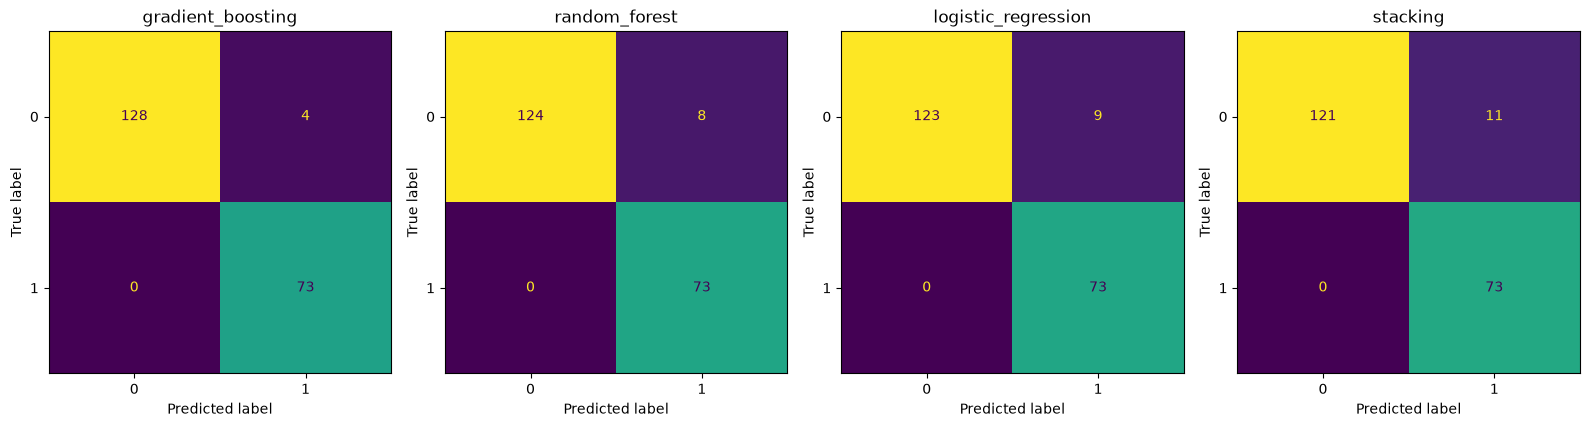

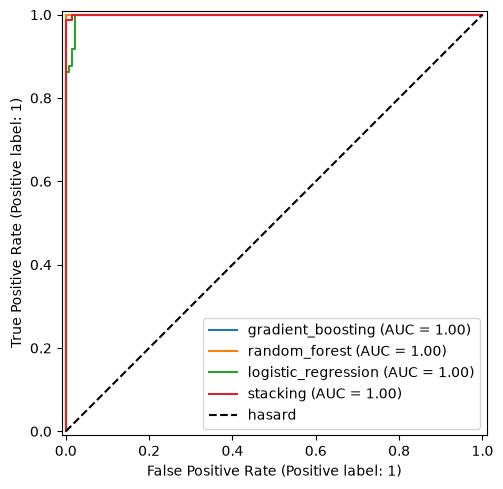

In [20]:
finalistes = {nom: entraines[nom] for nom in [choix, "random_forest", "logistic_regression", "stacking"]}
plot_confusion_matrices(finalistes, x_test, y_test, save_as="projet_matrices_confusion.png")
plot_roc_curves(finalistes, x_test, y_test, save_as="projet_courbes_roc.png")

### Compromis biais / variance

Les courbes d'apprentissage montrent le score sur le train et en validation croisée selon le nombre de cycles utilisés pour apprendre.

- Deux courbes basses et proches : le modèle est trop simple (**biais**).
- Une courbe train haute et une courbe validation nettement plus basse : le modèle apprend par coeur (**variance**).

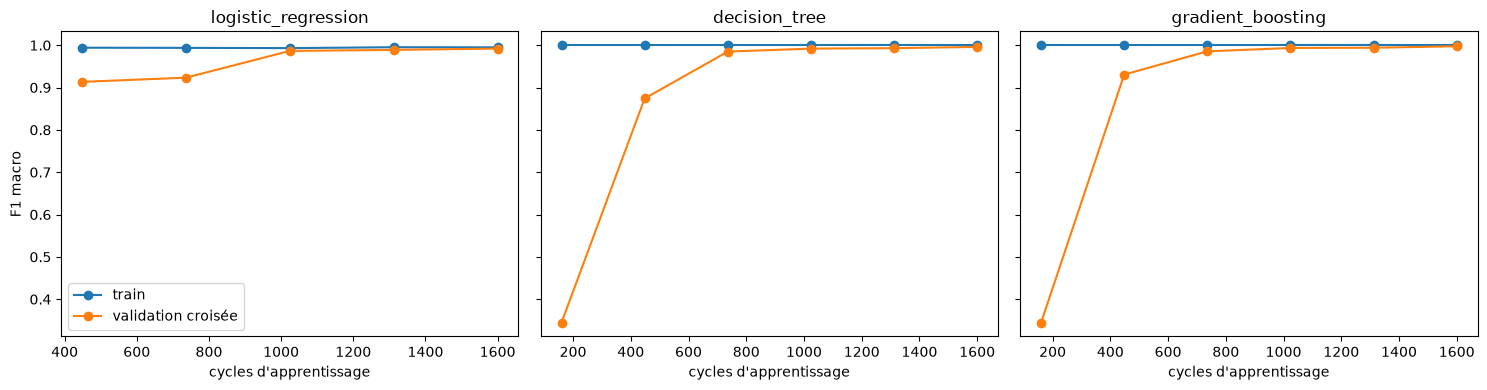

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, nom in zip(axes, ["logistic_regression", "decision_tree", choix]):
    tailles, sc_train, sc_val = learning_curve(entraines[nom], x_train, y_train, cv=cv,
                                               scoring="f1_macro", train_sizes=np.linspace(0.1, 1, 6))
    ax.plot(tailles, sc_train.mean(axis=1), "o-", label="train")
    ax.plot(tailles, sc_val.mean(axis=1), "o-", label="validation croisée")
    ax.set_title(nom)
    ax.set_xlabel("cycles d'apprentissage")
axes[0].set_ylabel("F1 macro")
axes[0].legend()
save_figure("projet_courbes_apprentissage.png")
plt.show()

## 11. Comprendre le modèle et ses erreurs

### 11.1 Quels cycles sont mal classés ?

In [22]:
pd.crosstab(profile["valve"][2000:], modele.predict(x_test),
            rownames=["état réel de la vanne (%)"], colnames=["prédiction (1 = optimale)"])

prédiction (1 = optimale),0,1
état réel de la vanne (%),,
73,40,0
80,42,0
90,46,4
100,0,73


### 11.2 Quelles features comptent ?

Importance par permutation : on mélange une feature et on mesure la baisse du F1 sur le test. Plus la baisse est forte, plus le modèle dépend de cette feature.

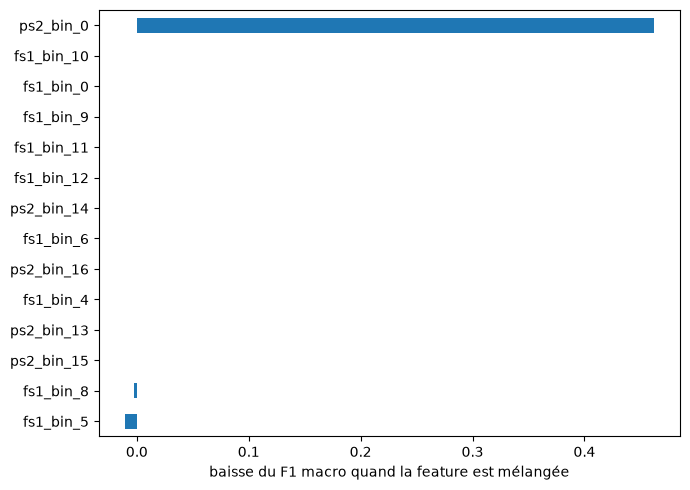

In [23]:
importance = permutation_importance(modele, x_test, y_test, n_repeats=10, random_state=42, scoring="f1_macro")
importance = pd.Series(importance.importances_mean, index=x_test.columns).sort_values()

importance.plot.barh(figsize=(7, 5))
plt.xlabel("baisse du F1 macro quand la feature est mélangée")
save_figure("projet_importance_features.png")
plt.show()

In [24]:
# Sens physique de ps2_bin_0 : part du cycle passée dans le premier intervalle de pression
bornes = np.linspace(PS2.values[:2000].min(), PS2.values[:2000].max(), 21)
print(f"ps2_bin_0 = part du cycle où la pression est entre {bornes[0]:.1f} et {bornes[1]:.1f} bar")

duree = pd.DataFrame({"vanne (%)": profile["valve"][:2000],
                      "secondes à basse pression": x_train["ps2_bin_0"] * 60})
duree.groupby("vanne (%)")["secondes à basse pression"].describe()[["mean", "min", "max"]].round(2)

ps2_bin_0 = part du cycle où la pression est entre 0.0 et 8.4 bar


,mean,min,max
vanne (%),,,
73,9.46,9.41,9.60
80,9.34,9.30,9.47
90,9.25,9.20,9.37
100,9.18,9.13,9.30


In [25]:
# Un seul seuil sur cette seule feature
regle = DecisionTreeClassifier(max_depth=1).fit(x_train[["ps2_bin_0"]], y_train)
seuil = regle.tree_.threshold[0]
print(f"Règle : vanne optimale si moins de {seuil * 60:.2f} s à basse pression")
print(f"Accuracy de cette règle sur le test : {(regle.predict(x_test[['ps2_bin_0']]) == y_test).mean():.3f}")

Règle : vanne optimale si moins de 9.22 s à basse pression
Accuracy de cette règle sur le test : 0.932


## 12. Conclusion